# 06. Prediction model

Goal: put the three models together into one forecast that runs from any start time:
**load (nb 03) + solar (nb 04) + battery (nb 05) → battery voltage over the next N hours.**

The load model needs two inputs the forecast doesn't have in advance: **Starlink on/off** and **speed over ground**. Both now come from **nb 01b (the mission, reverse-engineered)**: the Starlink schedule, the mode plan, and the mission legs with their speeds.

**Part 1. Inputs:** from nb 01b *(the Starlink schedule section moved there)*

**Part 2. Model**
- Forecast = mission (Starlink schedule + 1 m/s waypoints) → load (nb 03, k·v by default, motor off when not under way); solar curve (nb 04); battery model (Model B1, nb 05)

**Part 3. Prediction**, small pieces first
1. 24 h pieces, each starting from the measured voltage
2. The whole mission (17 days) in one free run
3. Isolating the error: the same forecast with perfect (measured) solar, perfect load, or both

battery1 = battery, battery2 ("thruster" in Tether) = total load, battery3 = solar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load, both links
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, Starlink rows only

# Starlink sessions: same rule as nb 03 (Starlink messages < 2 min apart = one session)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
sessions["minutes"] = (sessions.end - sessions.start).dt.total_seconds() / 60

MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
STARLINK_W = 22                                                  # nb 03
print(f"{len(sessions)} Starlink sessions, {sessions.start.min():%d %b %H:%M} to {sessions.end.max():%d %b %H:%M}")

159 Starlink sessions, 14 Jul 07:43 to 27 Jul 02:05


# Part 1. Inputs

The Starlink schedule, the mode plan and the mission legs are all in **nb 01b**. *(The Starlink schedule plot and table that used to be here moved there.)*

# Part 2. Model

Everything comes from a model, nothing from the telemetry except the **starting voltage**. Model numbers are copied by hand from the other notebooks (latest versions, 19 Nov); if those notebooks are refit, update the cell below.

**Inputs from the mission (nb 01b, `data/mission_*.csv`)**
- **Starlink on/off:** wakes at hh:47 on the scheduled hours for the phase's on-length (8 min every 2 h, then 16 min every 3 h, off after 27 Jul). The deployment phase had no schedule, so it uses its duty cycle: Starlink power × 0.44.
- **Motor on/off:** each run departs at its time and goes through its waypoints at **1 m/s**, so the motor is on for (run length in km) / 3.6 hours. The rest of the time the boat waits with the motor off (v = 0, the MANUAL load model).

**Load (nb 03, sections 3 and 3b):** P_load = 10 W hotel + 22 W · Starlink + motor · k · vⁿ, motor = 0 when not under way. Three motor models, picked with `LOAD_MODEL`:

| model | k | motor at 1 m/s | load under way (Starlink off / on) |
| --- | --- | --- | --- |
| **k·v** (default, best in nb 03) | 64.8 | 65 W | 75 / 97 W |
| k·v² | 54.4 | 54 W | 64 / 86 W |
| k·v³ (used before) | 39.3 | 39 W | 49 / 71 W |

Waiting: 10 W, or 32 W with Starlink. With the plan the speed is always 1 m/s when moving, so the three models differ only by k.

**Solar (nb 04):** 35.70 − 67.06·cos(ωt) − 9.32·sin(ωt), ω = 2π/24 h, t = UTC hour, clipped at 0. Same every day.

**Battery (nb 05, Model B1, the best free run there with measured inputs: RMSE 0.47 V):** k = 420 Wh/V, η = 1.14, drain −0.31 W, R = 39.2 mΩ, no charging above 25.0 V. η above 1 isn't physical; it's what the data asks for (a sensor calibration offset or a charge/discharge difference, not yet known), see nb 05.
- P_net = η·P_solar − P_load − P_drain
- OCV moves by P_net · dt / k; terminal V = OCV + R · P_net / V
- Start: OCV = measured voltage (median of readings within ± 30 min) − R · I_batt

In [2]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ---- models, copied by hand from the other notebooks (latest: 19 Nov) ----
HOTEL_W, V_NOMINAL = 10, 1.0                                       # nb 03 (STARLINK_W = 22 is set above)
LOAD_MODELS = {"k·v": (1, 64.81), "k·v²": (2, 54.41), "k·v³": (3, 39.32)}   # nb 03 section 3b: (power of v, k)
LOAD_MODEL = "k·v"                                                 # default: best in nb 03
SOLAR_A, SOLAR_B, SOLAR_C, OMEGA = 35.70, -67.06, -9.32, 2 * np.pi / 24   # nb 04
BATT = dict(k=420.3, eta=1.138, p_drain=-0.312, R=0.03921, v_max=25.0)  # nb 05, Model B1 (best free run with measured inputs)

sl_plan = pd.read_csv("../data/mission_starlink.csv", parse_dates=["from", "to"], keep_default_na=False).rename(columns={"from": "start"})
wps = pd.read_csv("../data/mission_waypoints.csv", parse_dates=["depart"])
wps["run"] = wps.depart.notna().cumsum()
runs = wps.groupby("run").agg(depart=("depart", "first"), km=("km", "sum"))
runs["end"] = runs.depart + pd.to_timedelta(runs.km * 1000 / V_NOMINAL, unit="s")

def mission_inputs(grid, load_model=LOAD_MODEL):
    """Per-minute Starlink share (0–1), speed (m/s), load and solar power (W) from the mission alone.
    Motor power = k·vⁿ only while under way; 0 otherwise (MANUAL load model)."""
    sl = np.zeros(len(grid))
    for r in sl_plan.itertuples():
        inside = (grid >= r.start) & (grid < r.to)
        if r.duty > 0:
            sl[inside] = r.duty
        elif r.wake_hours:
            hrs = [int(h) for h in r.wake_hours.split()]
            mins_after = (grid - grid.floor("h")).total_seconds() / 60 - 47
            sl[inside & grid.hour.isin(hrs) & (mins_after >= 0) & (mins_after < r.on_min)] = 1
    v = np.zeros(len(grid))
    for r in runs.itertuples():
        v[(grid >= r.depart) & (grid < r.end)] = V_NOMINAL
    h = (grid - grid.floor("D")).total_seconds() / 3600
    solar = np.clip(SOLAR_A + SOLAR_B * np.cos(OMEGA * h) + SOLAR_C * np.sin(OMEGA * h), 0, None)
    n, kp = LOAD_MODELS[load_model]
    motor = (v > 0).astype(float)
    p_motor = motor * kp * v ** n
    return pd.DataFrame({"starlink": sl, "v": v, "P_motor": p_motor, "P_load": HOTEL_W + STARLINK_W * sl + p_motor,
                         "P_solar": solar}, index=grid)

volts = df.dropna(subset=["voltage_battery1_v"]).set_index("t").voltage_battery1_v

def v_at(t, half="30min"):
    """Measured voltage at time t: median of the readings within ± 30 min (Iridium can be 15 min apart)."""
    return volts[t - pd.Timedelta(half): t + pd.Timedelta(half)].median()

# ---- measured inputs, for the isolation test (section 3) ----
MEAS_GRID = pd.date_range(df.t.min().floor("min"), df.t.max().ceil("min"), freq="1min")
_mins = df.set_index("t")[["P_load", "P_solar"]].resample("1min").mean().reindex(MEAS_GRID)
MEAS = pd.DataFrame(index=MEAS_GRID)
MEAS["P_load"] = _mins.P_load.interpolate(method="time").bfill().ffill()          # both links: good coverage
_h = (MEAS_GRID - MEAS_GRID.floor("D")).total_seconds() / 3600
_night = np.clip(SOLAR_A + SOLAR_B * np.cos(OMEGA * _h) + SOLAR_C * np.sin(OMEGA * _h), 0, None) == 0
_sol = _mins.P_solar.copy()
_sol[_night & _sol.isna()] = 0.0                                                    # no sun at night
LAST_SOLAR = df.dropna(subset=["P_solar"]).t.max()
MEAS["P_solar"] = _sol.interpolate(method="time", limit_area="inside")
MEAS["solar_src"] = np.where(_mins.P_solar.notna(), "measured", np.where(_night, "night (0)", "interpolated"))
MEAS.loc[MEAS.index > LAST_SOLAR, "P_solar"] = np.nan                              # Starlink gone after 27 Jul
MEAS.loc[MEAS.index > LAST_SOLAR, "solar_src"] = "model (no data)"

def forecast(start, hours, v0=None, load_model=LOAD_MODEL, solar_src="model", load_src="model"):
    """Battery voltage forecast, minute by minute, from `start` for `hours`.
    v0 = starting voltage (default: measured), load_model = one of LOAD_MODELS.
    solar_src / load_src = "model" (default) or "measured" (telemetry, for the isolation test).
    Measured solar falls back to the model where there is none (after Starlink stops on 27 Jul)."""
    start = pd.Timestamp(start)
    grid = pd.date_range(start.floor("min"), start + pd.Timedelta(hours=hours), freq="1min")
    f = mission_inputs(grid, load_model)
    if load_src == "measured":
        f["P_load"] = MEAS.P_load.reindex(grid).values
    if solar_src == "measured":
        f["P_solar"] = MEAS.P_solar.reindex(grid).fillna(f.P_solar).values
    if v0 is None:
        v0 = v_at(start)
    k, eta, pd_, R, vmax = BATT["k"], BATT["eta"], BATT["p_drain"], BATT["R"], BATT["v_max"]
    V, ocv = np.empty(len(grid)), None
    for i, (pl, ps) in enumerate(zip(f.P_load.values, f.P_solar.values)):
        p_net = eta * ps - pl - pd_
        if ocv is None:
            ocv = v0 - R * p_net / v0
        v = ocv + R * p_net / max(ocv, 1)
        if p_net > 0 and v > vmax:                       # charge cap: extra solar is lost
            p_net = max((vmax - ocv) / R, 0) * vmax
            v = max(min(v, vmax), ocv)
        V[i] = v
        ocv += p_net / 60 / k
    f["V"] = V
    return f

print(f"{len(runs)} runs, {runs.km.sum():.0f} km, motor on {(runs.end - runs.depart).sum().total_seconds() / 3600:.0f} h at 1 m/s; load model {LOAD_MODEL}")

12 runs, 345 km, motor on 96 h at 1 m/s; load model k·v


# Part 3. Prediction

## 1. 24 h pieces

Start at 00:00 UTC each day (14 Jul: first reading at 00:20), take the measured voltage there, and forecast 24 h with the model alone. Each panel is one day: black dots = measured battery voltage, red = forecast (load model `LOAD_MODEL`, default k·v). Blue shading = the mission says the motor is on (under way at 1 m/s); yellow ticks along the bottom = Starlink on in the forecast. The table below gives the error at the end of each day (actual − forecast) and the RMSE over the day.

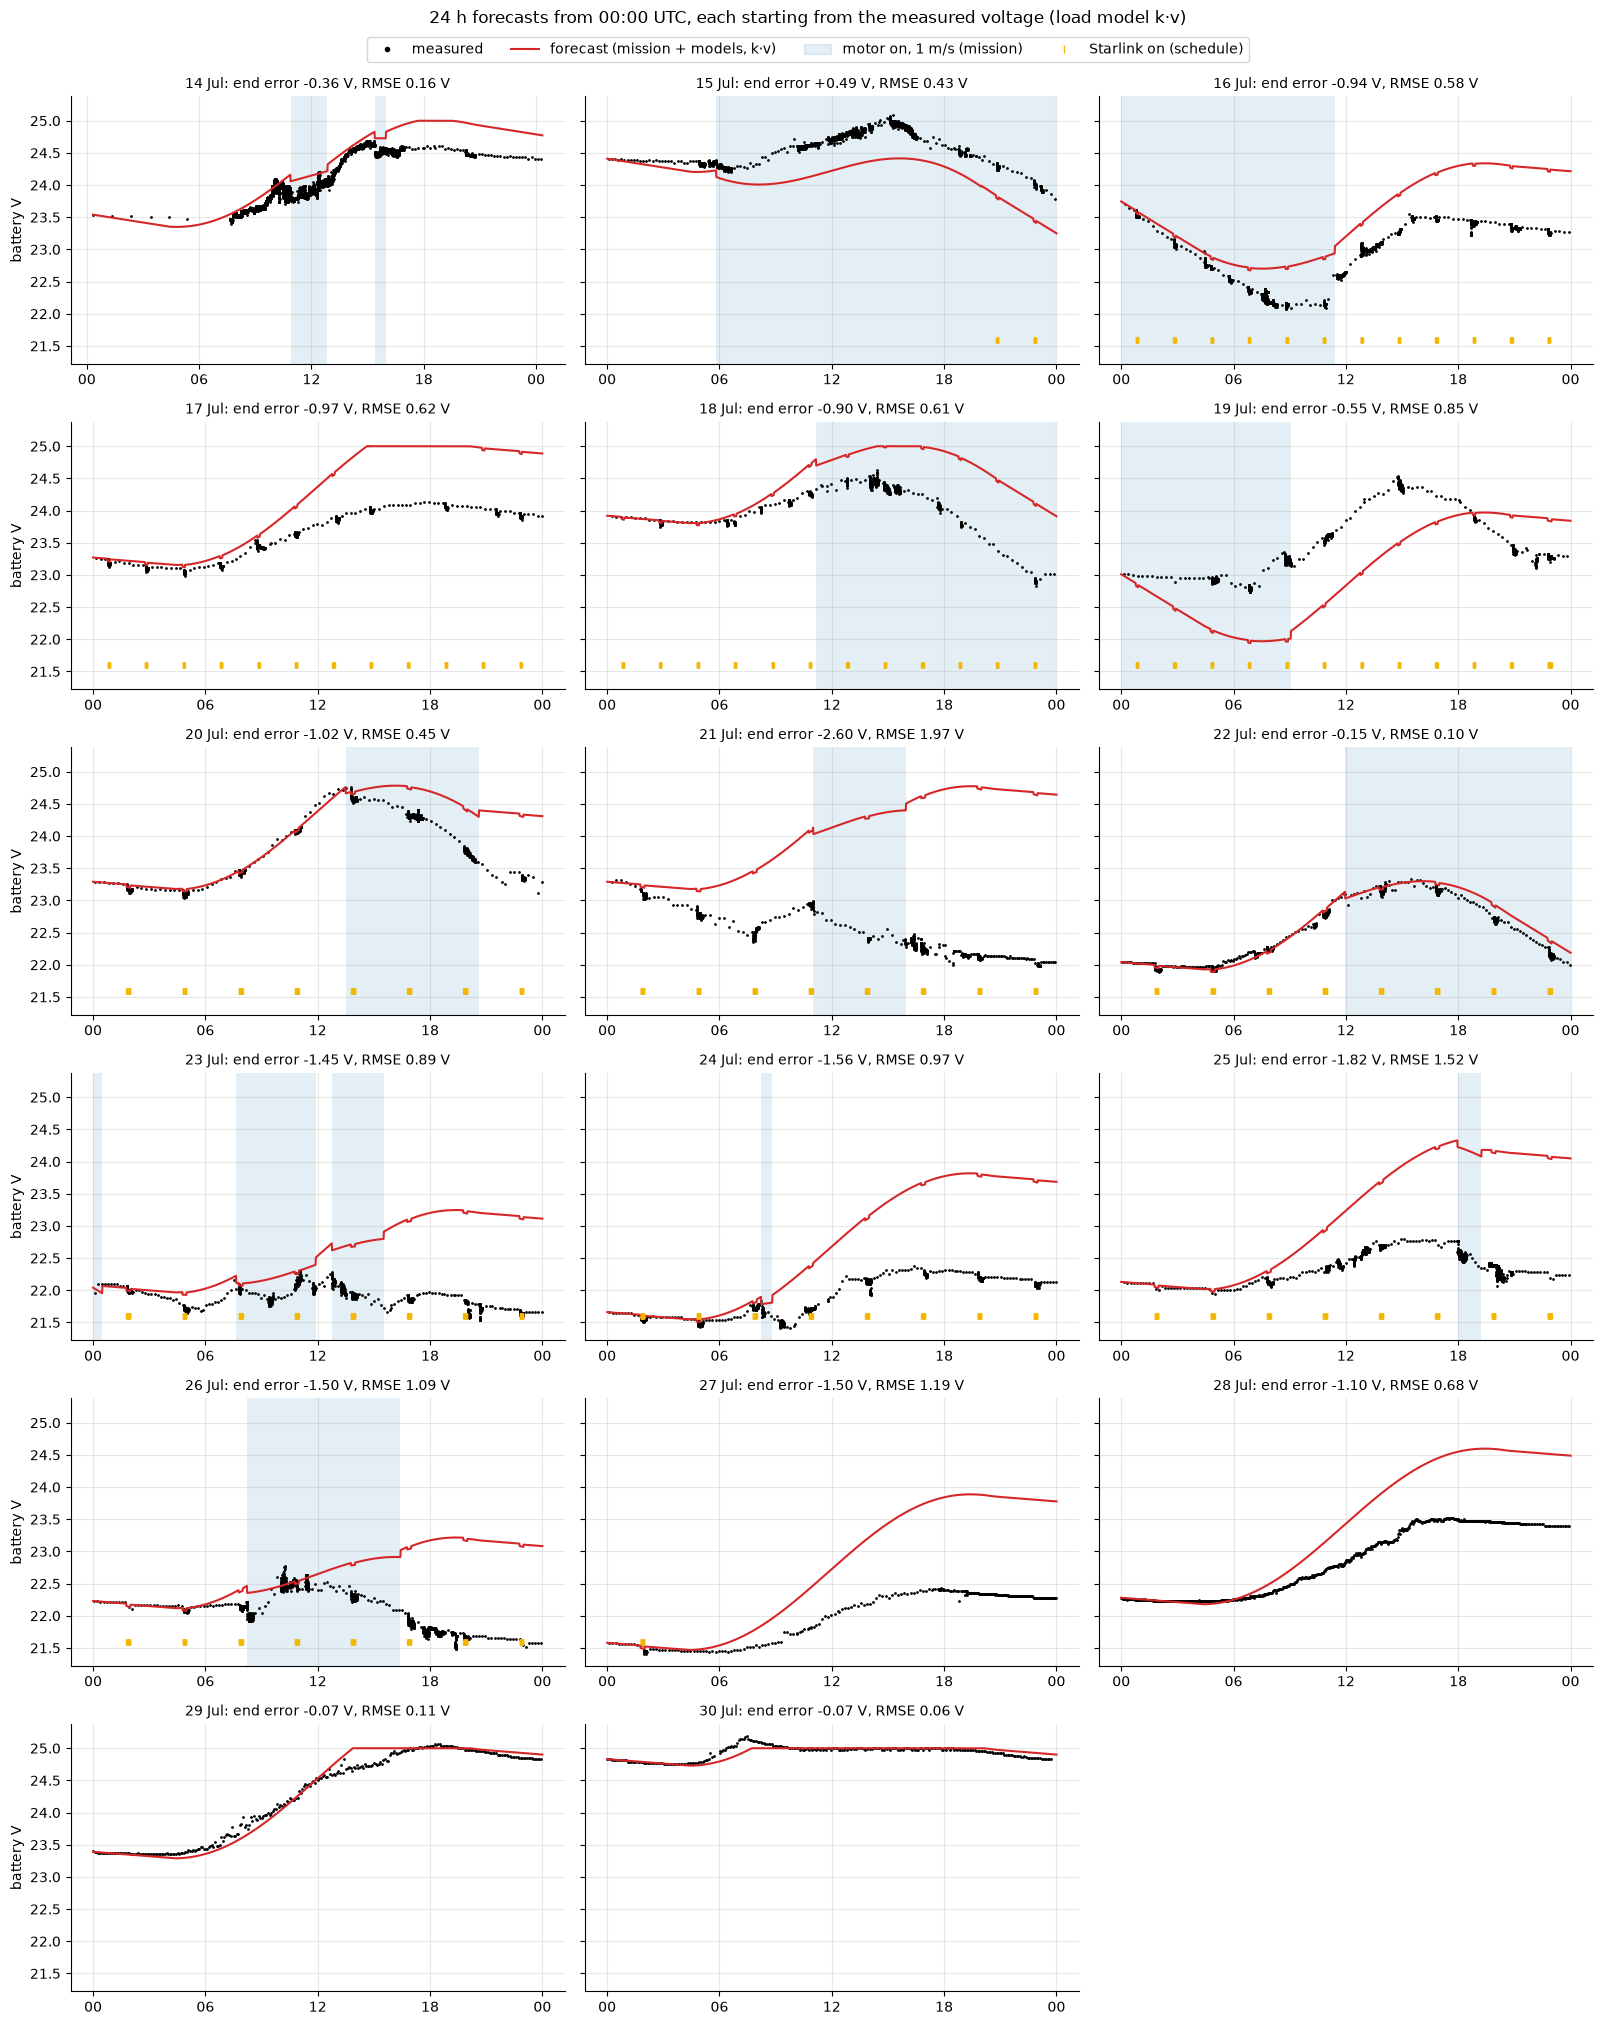

end error over 17 days: mean -0.95 V, mean |error| 1.00 V, RMSE 1.21 V


,V start,V end actual,V end forecast,RMSE (V),motor on (h),end error (V)
day,,,,,,
14 Jul,23.54,24.41,24.77,0.16,2.58,-0.36
15 Jul,24.41,23.74,23.25,0.43,18.18,0.49
16 Jul,23.75,23.27,24.21,0.58,11.42,-0.94
17 Jul,23.27,23.92,24.89,0.62,0.00,-0.97
18 Jul,23.92,23.01,23.91,0.61,12.85,-0.90
19 Jul,23.01,23.29,23.84,0.85,9.07,-0.55
20 Jul,23.29,23.29,24.31,0.45,7.12,-1.02
21 Jul,23.29,22.04,24.64,1.97,4.95,-2.60
22 Jul,22.04,22.04,22.19,0.10,12.05,-0.15


In [3]:
days = pd.date_range("2025-07-14", "2025-07-30", tz="UTC")
pieces, rows = {}, []
for d in days:
    start = max(d, volts.index[0])
    f = forecast(start, 24)
    a = volts[start: start + pd.Timedelta("24h")]
    e = a.values - f.V.reindex(a.index.floor("min")).values
    pieces[d] = (f, a)
    rows.append({"day": f"{d:%d %b}", "V start": f.V.iloc[0],
                 "V end actual": v_at(f.index[-1]),
                 "V end forecast": f.V.iloc[-1], "RMSE (V)": np.sqrt(np.nanmean(e ** 2)),
                 "motor on (h)": (f.v > 0).sum() / 60})
res = pd.DataFrame(rows).set_index("day")
res["end error (V)"] = res["V end actual"] - res["V end forecast"]

fig, axes = plt.subplots(6, 3, figsize=(16, 20), sharey=True)
for ax, (d, (f, a)) in zip(axes.flat, pieces.items()):
    on = (f.v > 0).values.astype(int)
    edges = np.flatnonzero(np.diff(np.r_[0, on, 0]))
    for s, e in zip(edges[::2], edges[1::2]):
        ax.axvspan(f.index[s], f.index[e - 1], color="#1f77b4", alpha=0.12, lw=0)
    ax.plot(a.index, a.values, ".", ms=2, color="k")
    ax.plot(f.index, f.V, color="#d62728", lw=1.5)
    sl = f.index[f.starlink >= 1]
    ax.plot(sl, np.full(len(sl), 21.6), "|", ms=5, color="#f2b701")
    r = res.loc[f"{d:%d %b}"]
    ax.set_title(f"{d:%d %b}: end error {r['end error (V)']:+.2f} V, RMSE {r['RMSE (V)']:.2f} V", fontsize=10)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
for ax in axes.flat[len(pieces):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("battery V")
fig.legend(handles=[Line2D([], [], marker=".", ls="", color="k", label="measured"),
                    Line2D([], [], color="#d62728", lw=1.5, label=f"forecast (mission + models, {LOAD_MODEL})"),
                    Patch(color="#1f77b4", alpha=0.12, label="motor on, 1 m/s (mission)"),
                    Line2D([], [], marker="|", ls="", color="#f2b701", label="Starlink on (schedule)")],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"24 h forecasts from 00:00 UTC, each starting from the measured voltage (load model {LOAD_MODEL})", y=1.01)
plt.tight_layout(); plt.show()

print(f"end error over {len(res)} days: mean {res['end error (V)'].mean():+.2f} V, "
      f"mean |error| {res['end error (V)'].abs().mean():.2f} V, RMSE {np.sqrt((res['end error (V)'] ** 2).mean()):.2f} V")
res.round(2)

**What we see (24 h pieces, load k·v, battery B1):**
- **End error: mean −0.95 V, mean |error| 1.00 V, RMSE 1.21 V.** The forecast is too high on almost every day.
- **Good days** (|end error| ≤ 0.4 V): 14, 22, 29, 30 Jul.
- **15 Jul ends 0.5 V too low** (forecast drains too much). It was a sunny day: measured solar between 06 and 18 UTC was about 1.5× the average-day model.
- **Worst: 21 Jul (−2.6 V) and 23–27 Jul (−1.5 to −1.8 V).** Cloudy days, where the fixed solar curve gives far too much sun (measured 0.5–0.75 of the model on 23–26 Jul), and the 8 h AUTO hold on 21 Jul that the plan counts as motor off.
- Section 3 splits this into solar and load.

## 2. The whole mission (17 days) in one free run

One forecast from the first voltage reading (14 Jul 00:20) to the end of the data, never corrected along the way. Top: measured voltage (dots) vs forecast (red), with the mission's motor-on time shaded blue. Bottom: error = actual − forecast, one dot per reading.

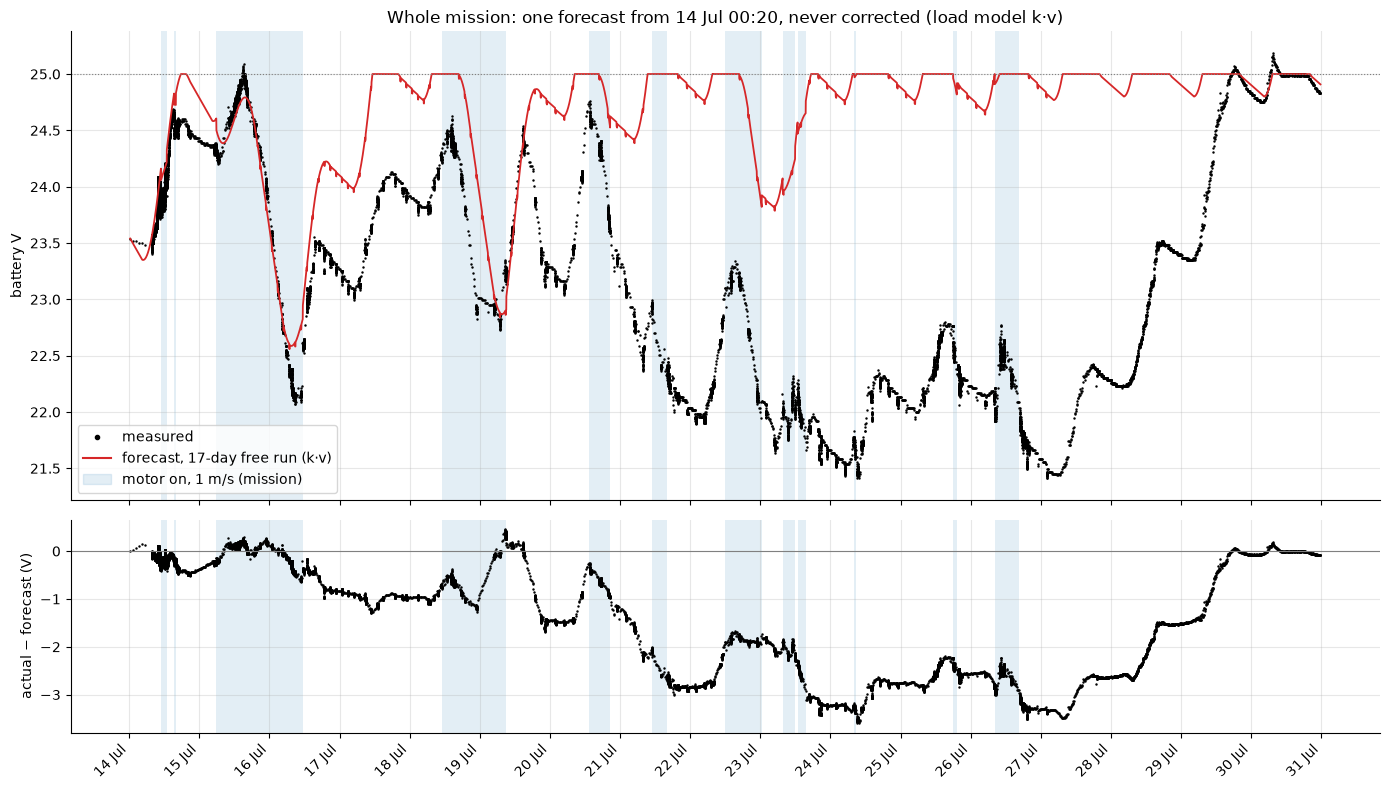

RMSE 1.54 V, mean error -1.00 V, max |error| 3.59 V
forecast energy over 17 days: solar in 19.7 kWh, load out 11.1 kWh (hotel 4.1, Starlink 0.8, propulsion 6.2)
hours at the 25 V cap: forecast 137 h


t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
mean error (V),-0.13,0.02,-0.42,-0.99,-0.79,-0.42,-0.97,-2.41,-2.33,-2.53,-3.09,-2.57,-2.98,-2.89,-2.12,-0.69,-0.01


In [4]:

t0, t1 = volts.index[0], volts.index[-1]
full = forecast(t0, (t1 - t0).total_seconds() / 3600)
err_full = volts.values - full.V.reindex(volts.index.floor("min")).values
err_full = pd.Series(err_full, index=volts.index)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
on = (full.v > 0).values.astype(int)
edges = np.flatnonzero(np.diff(np.r_[0, on, 0]))
for s, e in zip(edges[::2], edges[1::2]):
    for a in (ax, ax2):
        a.axvspan(full.index[s], full.index[e - 1], color="#1f77b4", alpha=0.12, lw=0)
ax.plot(volts.index, volts.values, ".", ms=1.5, color="k", label="measured")
ax.plot(full.index, full.V, color="#d62728", lw=1.3, label=f"forecast, 17-day free run ({LOAD_MODEL})")
ax.axhline(BATT["v_max"], color="grey", lw=0.8, ls=":")
ax.set_ylabel("battery V")
ax.legend(handles=[Line2D([], [], marker=".", ls="", color="k", label="measured"),
                   Line2D([], [], color="#d62728", lw=1.5, label=f"forecast, 17-day free run ({LOAD_MODEL})"),
                   Patch(color="#1f77b4", alpha=0.12, label="motor on, 1 m/s (mission)")], loc="lower left")
ax.set_title(f"Whole mission: one forecast from 14 Jul 00:20, never corrected (load model {LOAD_MODEL})")
ax2.plot(err_full.index, err_full.values, ".", ms=1.5, color="k")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − forecast (V)")
ax2.xaxis.set_major_locator(mdates.DayLocator()); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

e_in = full.P_solar.sum() / 60 * BATT["eta"] / 1000
e_out = full.P_load.sum() / 60 / 1000
print(f"RMSE {np.sqrt((err_full ** 2).mean()):.2f} V, mean error {err_full.mean():+.2f} V, max |error| {err_full.abs().max():.2f} V")
print(f"forecast energy over 17 days: solar in {e_in:.1f} kWh, load out {e_out:.1f} kWh "
      f"(hotel {HOTEL_W * len(full) / 60 / 1000:.1f}, Starlink {(STARLINK_W * full.starlink).sum() / 60 / 1000:.1f}, "
      f"propulsion {full.P_motor.sum() / 60 / 1000:.1f})")
print(f"hours at the 25 V cap: forecast {(full.V >= BATT['v_max'] - 0.01).sum() / 60:.0f} h")
daily_err = err_full.groupby(err_full.index.floor("D")).mean()
daily_err.set_axis(daily_err.index.strftime("%d %b")).round(2).to_frame("mean error (V)").T


**What we see (17 days, load k·v, battery B1):**
- **RMSE 1.54 V, mean error −1.00 V, max 3.6 V.**
- **14–20 Jul follows the shape roughly** (within about ±1 V): it drains during the motor runs (15–16 and 18–19 Jul) like the real battery.
- **From 21 Jul it drifts up to the 25 V cap** and stays there most days (137 h at the cap), while the real battery sinks to about 21.5 V. Error about −3 V on 23–27 Jul.
- **The cap hides how wrong the energy is.** Once the forecast is pinned at 25 V, extra solar is thrown away, so the error stops growing. That's also why it "comes back" on 29–30 Jul: the real battery charges up to the same cap.
- **Energy budget:** 19.7 kWh of solar into the battery (model solar × η 1.14) vs 11.1 kWh load out (hotel 4.1, motor 6.2, Starlink 0.8). In reality in ≈ out. Section 3 splits the gap between solar and load.

## 3. Isolating the error: perfect solar, perfect load

The 17-day run again, four ways. Battery model and starting voltage are the same in all four; only where solar and load come from changes:

| run | solar | load |
| --- | --- | --- |
| **forecast** (section 2) | model (nb 04) | model from the plan (nb 03, k·v) |
| **perfect solar** | measured | model from the plan |
| **perfect load** | model | measured |
| **both measured** | measured | measured |

- **Measured load** = battery1 V × battery2 A, per-minute mean, interpolated between readings. Both links carry it, so it's measured almost everywhere.
- **Measured solar** = battery3 V × A, which only comes over **Starlink**. Between sessions it's interpolated linearly, and set to 0 at night (where the solar model is 0). After Starlink stops for good (27 Jul 02:05) there's no solar data, so all runs use the solar model there (grey band).

If **perfect solar** fixes most of the error, the solar model is the problem; if **perfect load** does, the load model is. **Both measured** shows what's left over for the battery model itself (it's close to the nb 05 free run).

The plot has three panels: voltage, error (actual − forecast, hourly mean), and the **rate of error change** (hour-to-hour change of the hourly error, V per h). A spike in the bottom panel marks an hour where that run goes wrong fastest; positive = the real voltage rose faster (or fell slower) than the run.

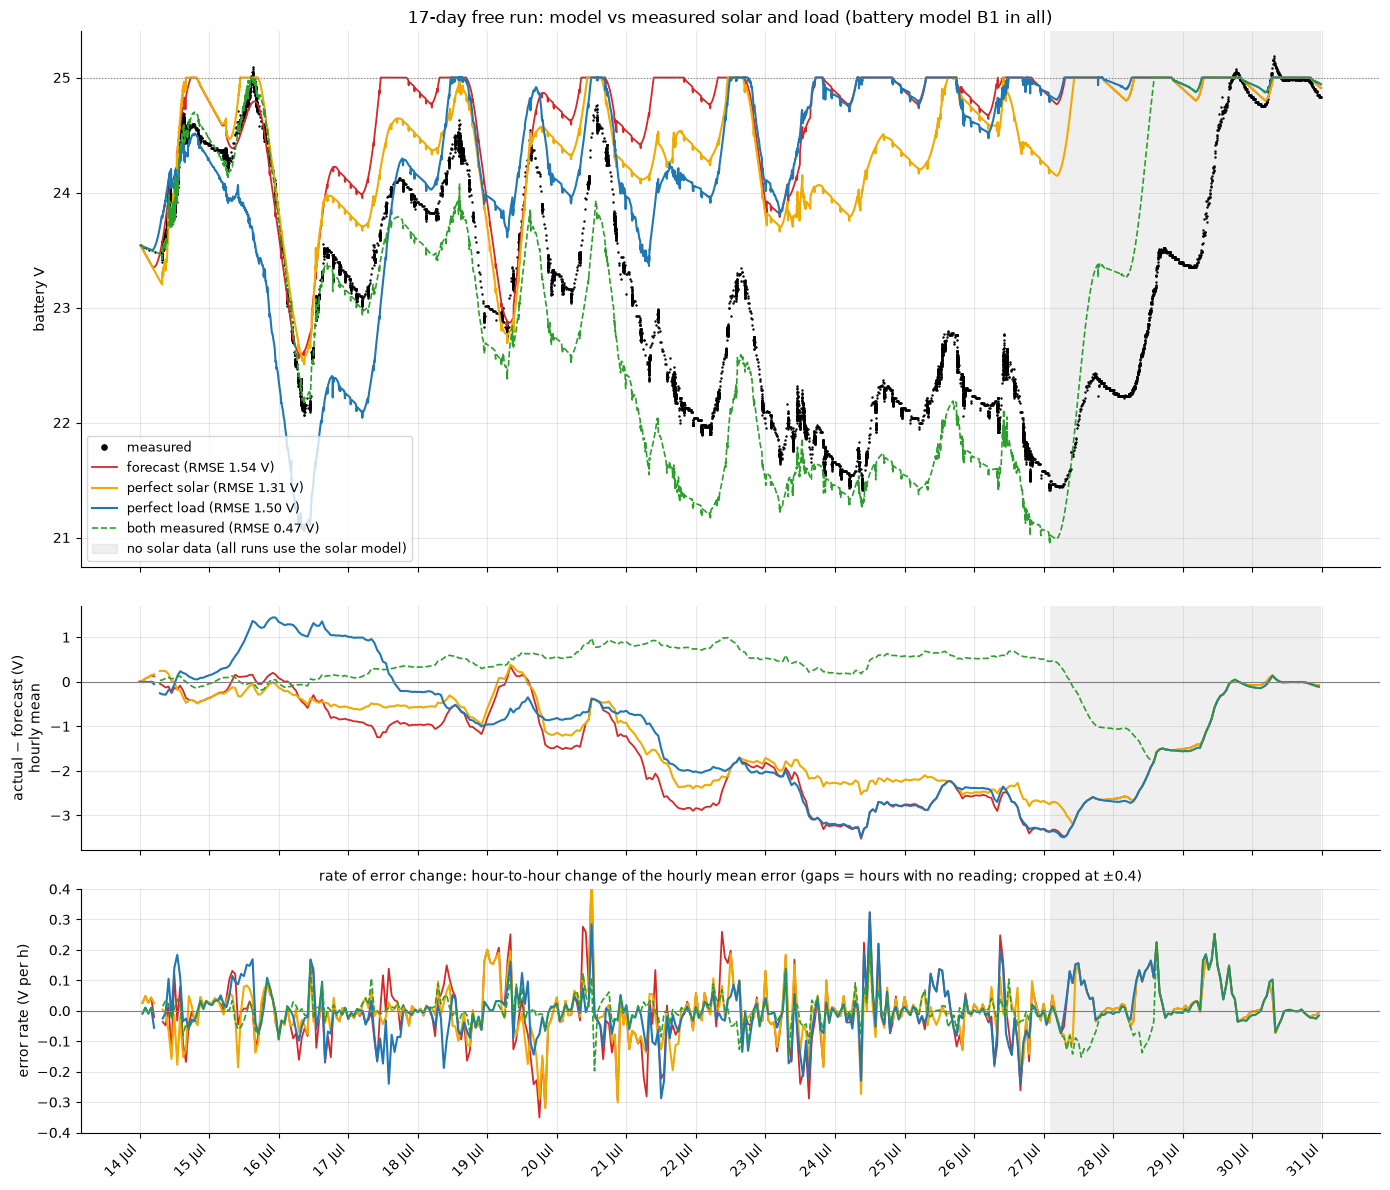

solar minutes to 27 Jul: {'interpolated': 10083, 'night (0)': 5838, 'measured': 2905}


,solar,load,17 days: RMSE (V),to 27 Jul: RMSE (V),to 27 Jul: mean error (V),24 h pieces to 27 Jul: mean |end error| (V),solar in to 27 Jul (kWh),load out to 27 Jul (kWh),hours at 25 V cap
run,,,,,,,,,
forecast,model,model,1.54,1.51,-0.96,1.10,15.08,10.18,137.05
perfect solar,measured,model,1.31,1.26,-0.71,0.37,11.54,10.18,73.05
perfect load,model,measured,1.50,1.46,-0.70,0.82,15.08,12.69,98.20
both measured,measured,measured,0.47,0.39,0.26,0.16,11.54,12.69,34.53


In [5]:
VARIANTS = {"forecast": ("model", "model"), "perfect solar": ("measured", "model"),
            "perfect load": ("model", "measured"), "both measured": ("measured", "measured")}
VAR_STYLE = {"forecast": dict(color="#d62728", lw=1.3), "perfect solar": dict(color="#f2a900", lw=1.5),
             "perfect load": dict(color="#1f77b4", lw=1.5), "both measured": dict(color="#2ca02c", lw=1.2, ls="--")}
hours_all = (t1 - t0).total_seconds() / 3600
runs_v, errs_v = {}, {}
for name, (s_src, l_src) in VARIANTS.items():
    runs_v[name] = forecast(t0, hours_all, solar_src=s_src, load_src=l_src)
    errs_v[name] = pd.Series(volts.values - runs_v[name].V.reindex(volts.index.floor("min")).values, index=volts.index)

fig, (ax, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
rate_v = {}
for a in (ax, ax2, ax3):
    a.axvspan(LAST_SOLAR, t1, color="grey", alpha=0.12, lw=0)
ax.plot(volts.index, volts.values, ".", ms=1.5, color="k", label="measured")
for name, f in runs_v.items():
    e = errs_v[name]
    ax.plot(f.index, f.V, label=f"{name} (RMSE {np.sqrt((e ** 2).mean()):.2f} V)", **VAR_STYLE[name])
    eh = e.resample("1h").mean()
    ax2.plot(eh.index, eh.values, **VAR_STYLE[name])
    rate_v[name] = eh.diff()                       # V per h; NaN across hours with no reading
    ax3.plot(rate_v[name].index, rate_v[name].values, **VAR_STYLE[name])
ax.axhline(BATT["v_max"], color="grey", lw=0.8, ls=":")
ax.set_ylabel("battery V")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + [Patch(color="grey", alpha=0.12, label="no solar data (all runs use the solar model)")],
          loc="lower left", fontsize=9, markerscale=5)
ax.set_title("17-day free run: model vs measured solar and load (battery model B1 in all)")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − forecast (V)\nhourly mean")
ax3.axhline(0, color="grey", lw=0.8)
ax3.set_ylim(-0.4, 0.4)
ax3.set_ylabel("error rate (V per h)")
ax3.set_title("rate of error change: hour-to-hour change of the hourly mean error (gaps = hours with no reading; cropped at ±0.4)", fontsize=10)
ax3.xaxis.set_major_locator(mdates.DayLocator()); ax3.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(ax3.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

before = volts.index <= LAST_SOLAR
iso = []
for name, f in runs_v.items():
    e = errs_v[name]
    ends = []
    for d in days:
        st = max(d, volts.index[0])
        if st + pd.Timedelta("24h") > LAST_SOLAR:
            continue
        g = forecast(st, 24, solar_src=VARIANTS[name][0], load_src=VARIANTS[name][1])
        ends.append(v_at(g.index[-1]) - g.V.iloc[-1])
    ends = pd.Series(ends).dropna()
    sel = f.index <= LAST_SOLAR
    iso.append({"run": name, "solar": VARIANTS[name][0], "load": VARIANTS[name][1],
                "17 days: RMSE (V)": np.sqrt((e ** 2).mean()),
                "to 27 Jul: RMSE (V)": np.sqrt((e[before] ** 2).mean()), "to 27 Jul: mean error (V)": e[before].mean(),
                "24 h pieces to 27 Jul: mean |end error| (V)": ends.abs().mean(),
                "solar in to 27 Jul (kWh)": (BATT["eta"] * f.P_solar[sel]).sum() / 60 / 1000,
                "load out to 27 Jul (kWh)": f.P_load[sel].sum() / 60 / 1000,
                "hours at 25 V cap": (f.V >= BATT["v_max"] - 0.01).sum() / 60})
print("solar minutes to 27 Jul:", MEAS.loc[MEAS.index <= LAST_SOLAR, "solar_src"].value_counts().to_dict())
pd.DataFrame(iso).set_index("run").round(2)


**What we see (isolation, battery B1):**
- **Both measured is now the best run: RMSE 0.39 V to 27 Jul, 0.16 V mean |end error| on 24 h pieces.** With real solar and real load, battery model B1 follows the real voltage (it's the same run as the nb 05 free run). So the battery model is good enough to judge the inputs with.
- **On 24 h pieces, solar is the bigger problem.** Perfect solar cuts the error from 1.10 to **0.37 V**; perfect load only to 0.82 V.
- **Over 17 days, both are needed.** Perfect solar alone (1.26 V) and perfect load alone (1.46 V) still drift up to the cap from 21 Jul; only fixing both gets down to 0.39 V.
- **Solar model: too sunny.** Solar into the battery up to 27 Jul is 15.1 kWh with the model vs 11.5 kWh measured (both × η), about 30% too much, and it can't tell sunny days (14–15 Jul, about 1.5× the model) from cloudy ones (17 and 24–26 Jul, about 0.5×).
- **Plan load: too low.** 10.2 kWh vs 12.7 kWh measured up to 27 Jul (holds counted as motor off, motor power at 1 m/s and timing, see nb 03).
- After 27 Jul there's no solar data, so every run uses the solar model and climbs to the cap ahead of the real battery (grey band).

### Which part of the day goes wrong?

The same error rates folded onto one day: for each UTC hour, the mean error rate (V per h) over all days **up to 27 Jul** (after that there's no solar data and every run uses the solar model). Left: mean error rate by hour of day. Right: the same, added up from midnight, i.e. how much error a typical day builds by each hour. The yellow band is when the solar model is above 0 (about 04:30 to 20:30 UTC).

Positive = the real voltage rose faster (or fell slower) than the run; negative = the run rose too fast (too much solar or too little load).

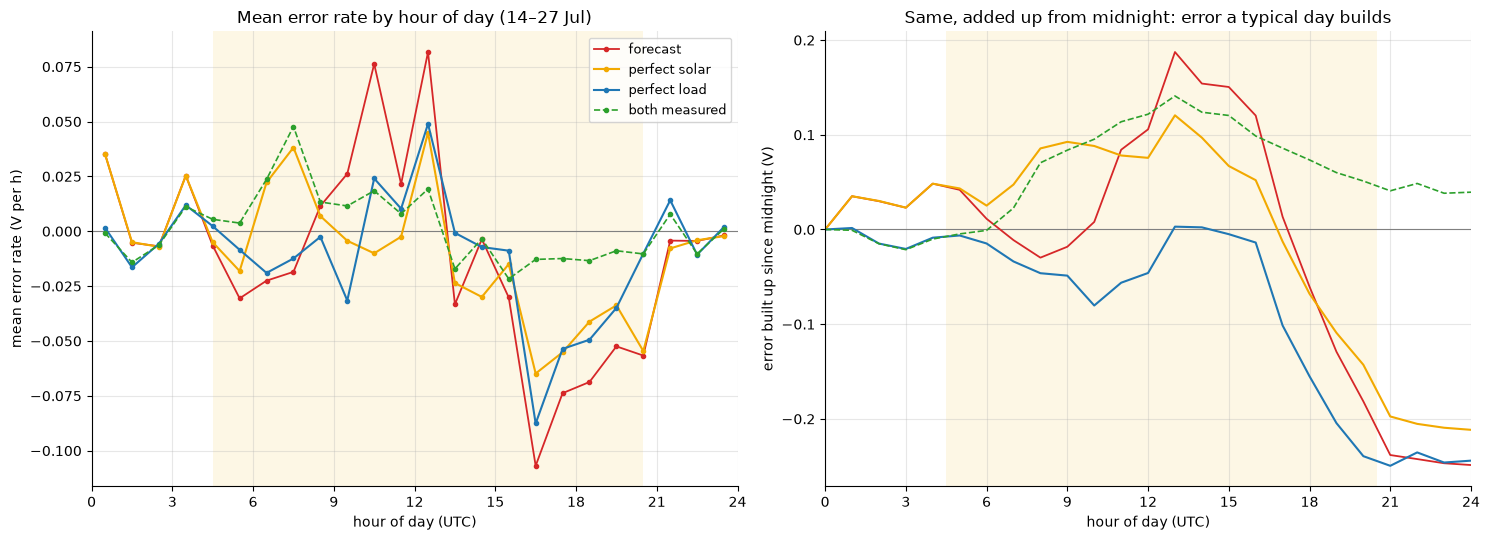

error built per typical day (V), by part of the day (sum of the hourly mean rates):


,night 00–04:30,day 05–20,evening 21–24,whole day
forecast,0.042,-0.280,-0.011,-0.249
perfect solar,0.043,-0.241,-0.014,-0.212
perfect load,-0.006,-0.243,0.005,-0.244
both measured,-0.005,0.046,-0.001,0.039


In [6]:
hr_rate = {}
for name, r in rate_v.items():
    r = r[r.index <= LAST_SOLAR]
    hr_rate[name] = r.groupby(r.index.hour).agg(["mean", "count"])
hh_ = np.arange(24)
sun = np.clip(SOLAR_A + SOLAR_B * np.cos(OMEGA * hh_) + SOLAR_C * np.sin(OMEGA * hh_), 0, None) > 0

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
for a in (a1, a2):
    a.axvspan(4.5, 20.5, color="#f2b701", alpha=0.10, lw=0)
    a.axhline(0, color="grey", lw=0.8)
for name, t in hr_rate.items():
    a1.plot(t.index + 0.5, t["mean"], marker="o", ms=3, **VAR_STYLE[name], label=name)
    a2.plot(np.r_[0, t.index + 1], np.r_[0, t["mean"].fillna(0).cumsum()], **VAR_STYLE[name], label=name)
a1.set_ylabel("mean error rate (V per h)")
a1.set_title("Mean error rate by hour of day (14–27 Jul)")
a2.set_ylabel("error built up since midnight (V)")
a2.set_title("Same, added up from midnight: error a typical day builds")
for a in (a1, a2):
    a.set_xlim(0, 24); a.set_xticks(range(0, 25, 3)); a.set_xlabel("hour of day (UTC)")
a1.legend(fontsize=9)
plt.tight_layout(); plt.show()

day_tab = pd.DataFrame({name: {"night 00–04:30": t.loc[0:4, "mean"].sum(), "day 05–20": t.loc[5:20, "mean"].sum(),
                               "evening 21–24": t.loc[21:23, "mean"].sum(), "whole day": t["mean"].sum()}
                        for name, t in hr_rate.items()}).T
print("error built per typical day (V), by part of the day (sum of the hourly mean rates):")
day_tab.round(3)

**What we see (time of day, 14–27 Jul, battery B1):**
- **Night (21:00–04:30) is fine for every run** (under ±0.05 V per typical night).
- **Both measured is nearly flat all day** (+0.04 V per typical day): with real inputs, no part of the day goes wrong.
- **The forecast's error is built in the afternoon.** It's ahead by about +0.19 V at 13:00, then loses about 0.45 V between 13:00 and 21:00 (worst around 16–17 h, −0.1 V per h). Net −0.25 V per typical day, which over 13 days is the −3 V drift.
- **Solar and load both go wrong in the afternoon, by about the same amount:**
  - **Perfect load** (model solar) is negative at 15–20 h → the solar model gives **too much late-afternoon sun**. It's a symmetric curve around 12:30 UTC, and the real afternoon fades faster. It's also negative in the early morning (05–10 h): too much morning sun as well.
  - **Perfect solar** (plan load) is negative at 16–20 h → the plan's load is **too low in the afternoon**. That fits mode 17 and motor use peaking in the afternoon (nb 01), which the 1 m/s plan doesn't capture.
- So the two fixes to try: a solar curve that's lower overall and fades faster after midday, and a plan load with more motor in the afternoon.